<a href="https://colab.research.google.com/github/Moon-JB/26-2-DIP-202201276/blob/main/HW02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Image Restoration

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/DIP4E'

Mounted at /content/drive


In [3]:
f = plt.imread(imgpath+'/test-pattern.tif')
f.shape

(604, 604)

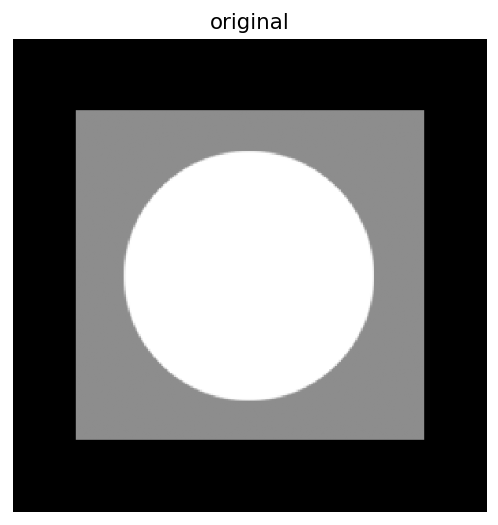

In [4]:
plt.figure(dpi=128)
plt.imshow(f, cmap='gray', aspect = 'equal')
plt.axis('off')
plt.title('original')
plt.show()

### Gaussian Noise

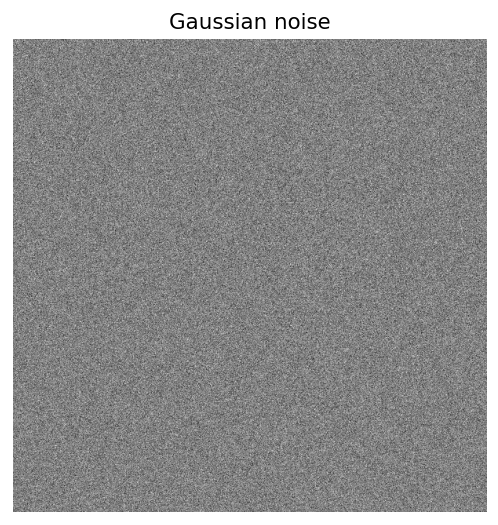

In [5]:
n_gauss = np.random.normal(0,32,f.shape)
plt.figure(dpi=128)
plt.imshow(n_gauss, cmap='gray', aspect = 'equal')
plt.axis('off')
plt.title('Gaussian noise')
plt.show()

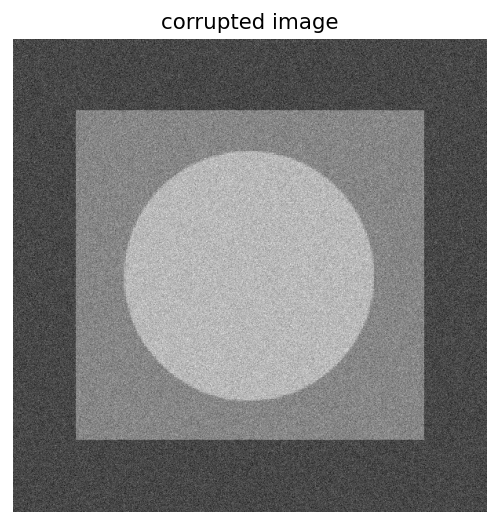

In [6]:
f_n = f + n_gauss
plt.figure(dpi=128)
plt.imshow(f_n,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('corrupted image')
plt.show()

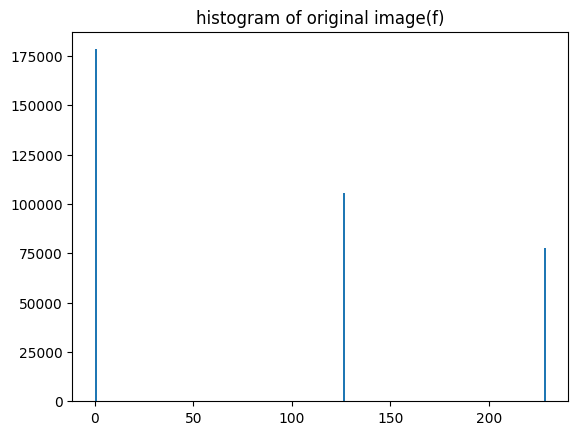

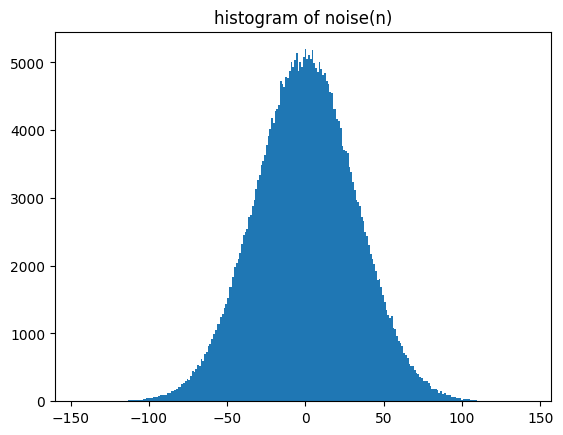

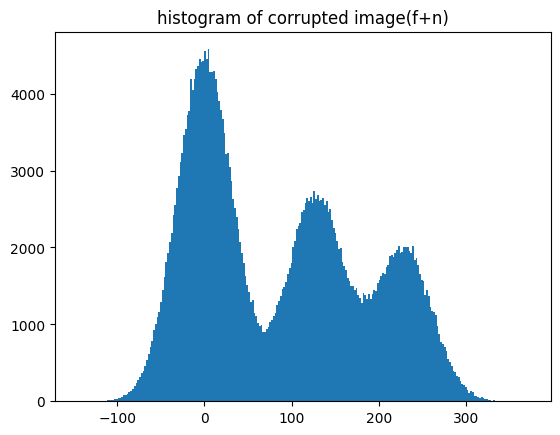

In [7]:
plt.hist(f.ravel(),256)
plt.title('histogram of original image(f)')
plt.show()
plt.hist(n_gauss.ravel(),256)
plt.title('histogram of noise(n)')
plt.show()
plt.hist(f_n.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

### Salt and Pepper Noise

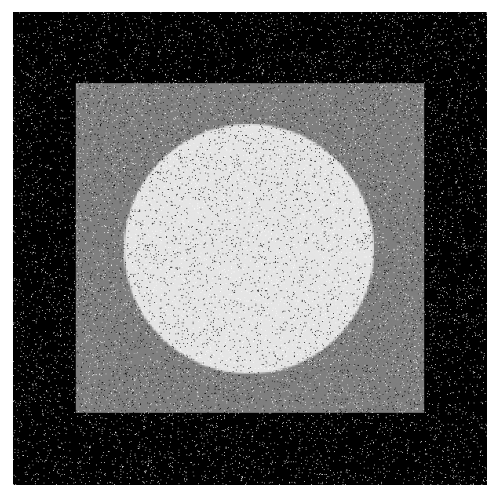

In [8]:
sp = np.random.randint(0,100,np.shape(f))
f_sp = f.copy()
f_sp[sp<3] = 0
f_sp[sp>96] = 255

plt.figure(dpi=128)
plt.imshow(f_sp,cmap='gray',aspect='equal')
plt.axis('off')
plt.show()

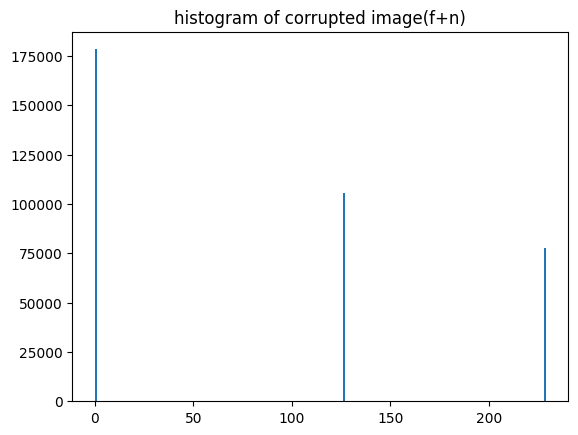

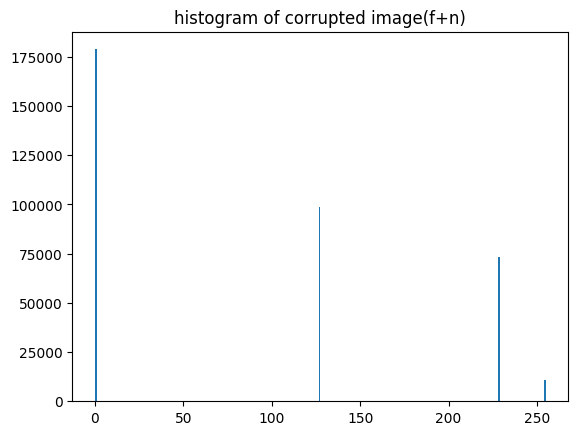

In [9]:
plt.hist(f.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

plt.hist(f_sp.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

### Mean vs Median Filtering

In [10]:
SS = 7 # kernel size (square kernel)
ss = int((SS-1)/2)
r_median = np.zeros(np.shape(f_sp))
r_mean = np.zeros(np.shape(f_sp))

In [11]:
for x in range(ss,np.size(f_sp,0)-ss):
  for y in range(ss,np.size(f_sp,1)-ss):
    Sxy = f_sp[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)
    r_median[x,y] = np.median(Sxy)

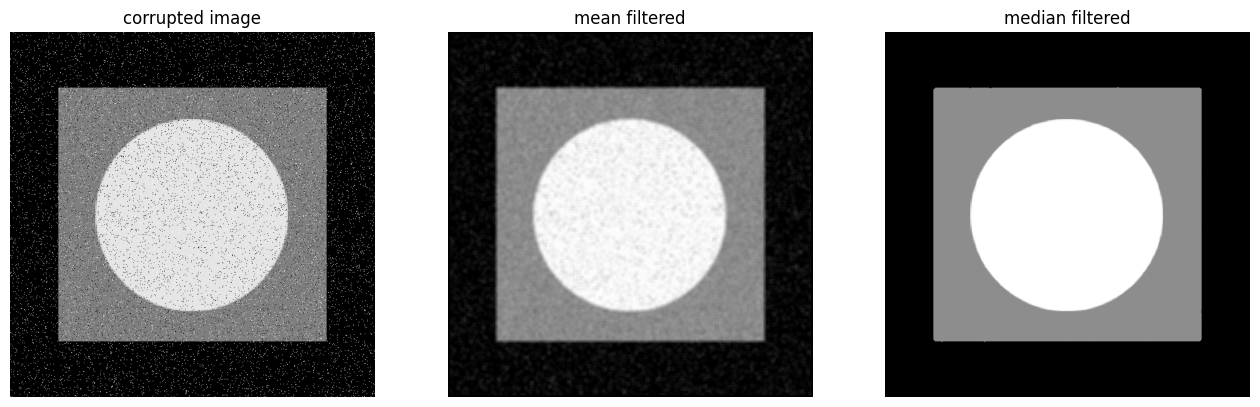

In [12]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f_sp,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_mean,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('mean filtered')
plt.subplot(133)
plt.imshow(r_median,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('median filtered')
plt.show()

## Adaptive Local Noise Reduction

In [13]:
# Adaptive local noise reduction
f = f_n

std_eta = 16
SS = 5

ss = int((SS-1)/2)
r_amean = np.zeros(np.shape(f))
for x in range(ss,np.size(f,0)-ss):
  for y in range(ss,np.size(f,1)-ss):
    Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)
    std_Sxy = np.std(Sxy)
    r_amean[x,y]=f[x,y]-((std_eta*std_eta)/(std_Sxy*std_Sxy))*(f[x,y]-np.mean(Sxy))

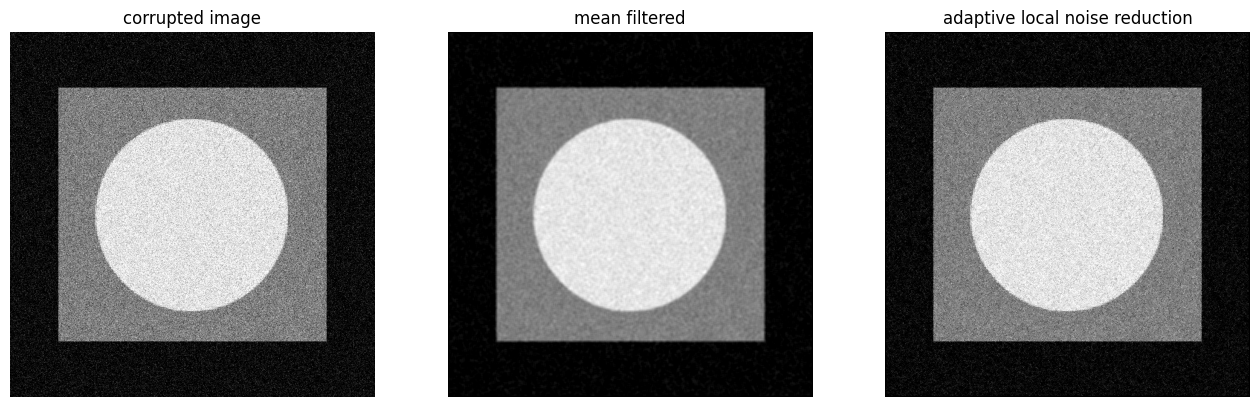

In [14]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f_n,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_mean,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('mean filtered')
plt.subplot(133)
plt.imshow(r_amean,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('adaptive local noise reduction')
plt.show()

## Adaptive Median Filtering

In [15]:
# Adaptive Median Filtering
#f = f_sp
f = plt.imread(imgpath+'/circuitboard-saltandpep.tif')
SS_vals = np.array([3, 5, 7])
r_amedian = np.zeros(np.shape(f))
r_median = np.zeros(np.shape(f))
r_case = np.zeros(np.shape(f))

ss_max = int((np.max(SS_vals)-1)/2)
for x in range(ss_max,np.size(f,0)-ss_max):
  for y in range(ss_max,np.size(f,1)-ss_max):
    flag_go = 1
    cnt = 0
    z_xy = f[x,y]
    for SS in SS_vals:
      ss = int((SS-1)/2)
      Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
      z_med = np.median(Sxy)
      z_min = np.min(Sxy)
      z_max = np.max(Sxy)

      if cnt==0:
        r_median[x,y] = z_med

      if z_min<z_med and z_med<z_max:
        if z_min<z_xy and z_xy<z_max:
          r_amedian[x,y] = z_xy
          flag_go = 0
        else:
          r_amedian[x,y] = z_med
          flag_go = 0
      else:
        if SS == np.max(SS_vals):
          r_amedian[x,y] = z_med
          flag_go = 0

      if flag_go==0:
        r_case[x,y] = cnt
        break
      cnt = cnt+1

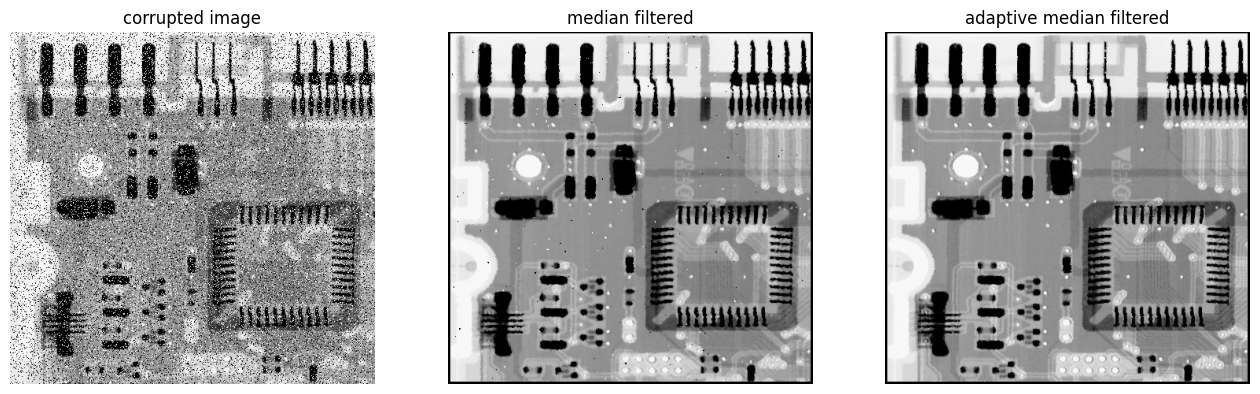

In [16]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_median,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('median filtered')
plt.subplot(133)
plt.imshow(r_amedian,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('adaptive median filtered')
plt.show()

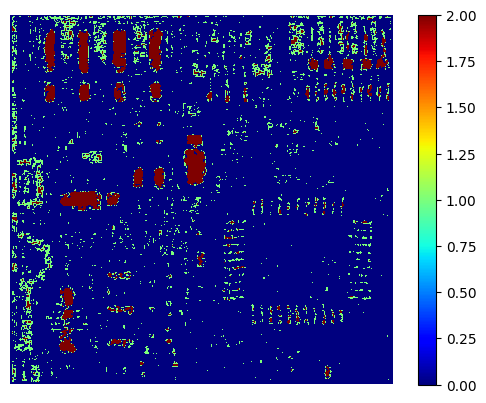

In [17]:
plt.imshow(r_case,cmap='jet',interpolation='nearest')
plt.axis('off')
plt.colorbar()
plt.show()

## Exercise
- 두 개의 noisy image를 각각 f1, f2로 불러오고 적절한 restoration(denoising)을 수행해보자.

In [20]:
from scipy import ndimage
from skimage import io

f1 = io.imread(imgpath + '/galaxy-pair-noisy.tif')
f2 = io.imread(imgpath + '/dentalXray-pepper-noise.tif')

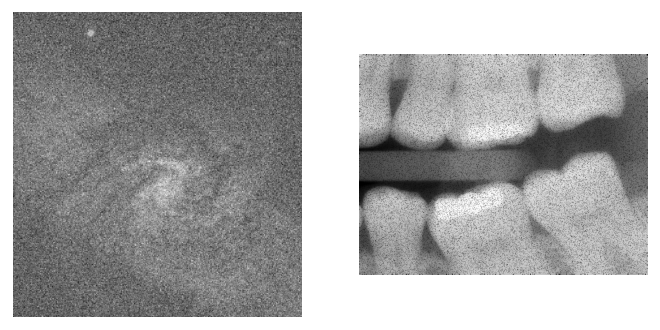

In [21]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')

plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2,cmap='gray')
plt.axis('off')
plt.show()

- 복원코드를 직접 작성해보기.

In [24]:
# 1. Arithmetic Mean Filter

f1_r = ndimage.uniform_filter(f1.astype(float), size=3)
f2_r = ndimage.uniform_filter(f2.astype(float), size=3)

In [23]:
# 2. Median Filter

f1_r = ndimage.median_filter(f1, size=3)
f2_r = ndimage.median_filter(f2, size=3)

In [26]:
# 3. Adaptive Local Noise Reduction

def adaptive_local_noise_reduction(img, size=7):
    img = img.astype(float)

    # 각 픽셀 주변의 국소 평균
    local_mean = ndimage.uniform_filter(img, size=size)

    # 각 픽셀 주변의 국소 제곱 평균
    local_mean_sq = ndimage.uniform_filter(img**2, size=size)

    # 국소 분산 = E[x^2] - E[x]^2
    local_var = np.maximum(local_mean_sq - local_mean**2, 0)

    # 전체 영상에서 잡음 분산 추정
    noise_var = np.mean(local_var)

    # 적응적 잡음 제거
    result = img - noise_var / (local_var + 1e-10) * (img - local_mean)

    return np.clip(result, 0, 255)

f1_r = adaptive_local_noise_reduction(f1)
f2_r = adaptive_local_noise_reduction(f2)

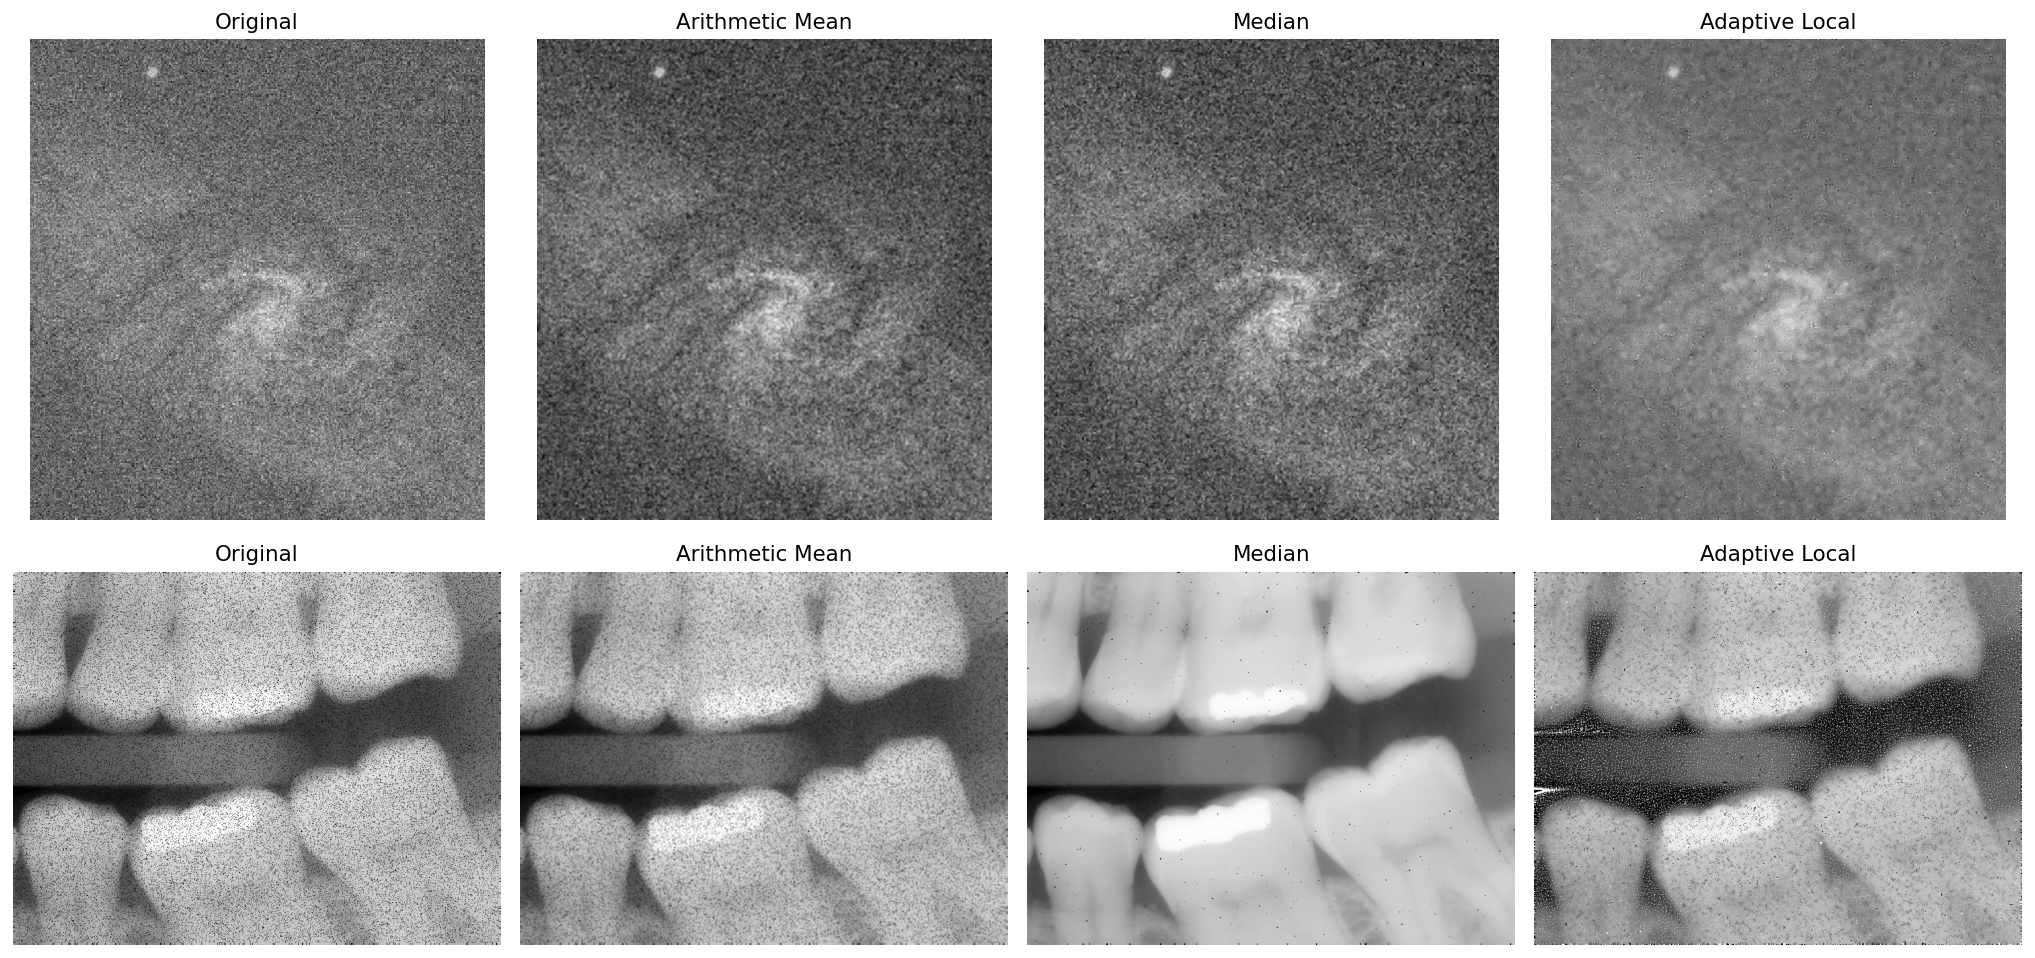

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# 1. Arithmetic Mean Filter
def arithmetic_mean(img):
    return ndimage.uniform_filter(img.astype(float), size=3)

# 2. Median Filter
def median(img):
    return ndimage.median_filter(img, size=3)

# 3. Adaptive Local Noise Reduction
def adaptive_local_noise_reduction(img, size=7):
    img = img.astype(float)

    local_mean = ndimage.uniform_filter(img, size=size)
    local_mean_sq = ndimage.uniform_filter(img**2, size=size)
    local_var = np.maximum(local_mean_sq - local_mean**2, 0)

    # 잡음 분산 추정
    noise_var = np.mean(local_var)

    result = img - (noise_var / (local_var + 1e-10)) * (img - local_mean)

    return np.clip(result, 0, 255)


# 필터링 결과 계산
images = [f1, f2]
titles = ['Original', 'Arithmetic Mean', 'Median', 'Adaptive Local']

results = [
    [f1, arithmetic_mean(f1), median(f1),
     adaptive_local_noise_reduction(f1)],
    [f2, arithmetic_mean(f2), median(f2),
     adaptive_local_noise_reduction(f2)]
]

# 시각화: 2행 x 4열
fig, axes = plt.subplots(2, 4, figsize=(16, 8), dpi=128)

for i in range(2):
    for j in range(4):
        axes[i, j].imshow(results[i][j], cmap='gray')
        axes[i, j].set_title(titles[j])
        axes[i, j].axis('off')

axes[0, 0].set_ylabel('Galaxy', fontsize=12)
axes[1, 0].set_ylabel('Dental X-ray', fontsize=12)

plt.tight_layout()
plt.show()

- 복원된 f1, f2를 시각화하기

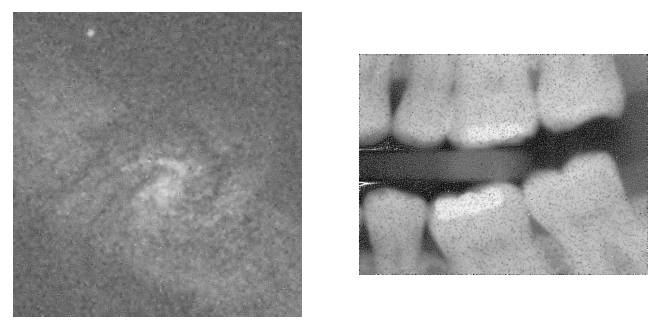

In [27]:
# f1_r: denoised f1
# f2_r: denoised f2
plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1_r,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2_r,cmap='gray')
plt.axis('off')
plt.show()

- 복원된 f1, f2를 그림파일로 저장하기

In [ ]:
plt.imsave('denoised-galaxy-pair.png',f1_r,cmap='gray')
plt.imsave('denoised-dentalXray.png',f2_r,cmap='gray')